# Feature selection algorithms comparison
Comparing different supervised feature selection methods for classification problems, using conventional flat features.

In [2]:
import pandas as pd
rankdata = pd.read_csv('./data/rankdata.csv')
rankdata.head()

,cpu_time,feature_index,feature_rank,ranking_method,adapter,directory,path,replica_no,replicas,description,name,p,n,p_informative
0,3.855204,0,4.0,RFE w/XGBoost,rebate,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,1,24,"Continuous Features [p=20,n=1600,h=0.4,edm=Easy]",Continuous Features,20,1600,"18,19"
1,3.855204,1,11.0,RFE w/XGBoost,rebate,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,1,24,"Continuous Features [p=20,n=1600,h=0.4,edm=Easy]",Continuous Features,20,1600,"18,19"
2,3.855204,2,5.0,RFE w/XGBoost,rebate,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,1,24,"Continuous Features [p=20,n=1600,h=0.4,edm=Easy]",Continuous Features,20,1600,"18,19"
3,3.855204,3,3.0,RFE w/XGBoost,rebate,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,1,24,"Continuous Features [p=20,n=1600,h=0.4,edm=Easy]",Continuous Features,20,1600,"18,19"
4,3.855204,4,11.0,RFE w/XGBoost,rebate,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,1,24,"Continuous Features [p=20,n=1600,h=0.4,edm=Easy]",Continuous Features,20,1600,"18,19"


## Ranking results
Measured cpu runtime on the ranking process.

Text(0.5, 1.0, 'cpu time per ranking method in seconds')

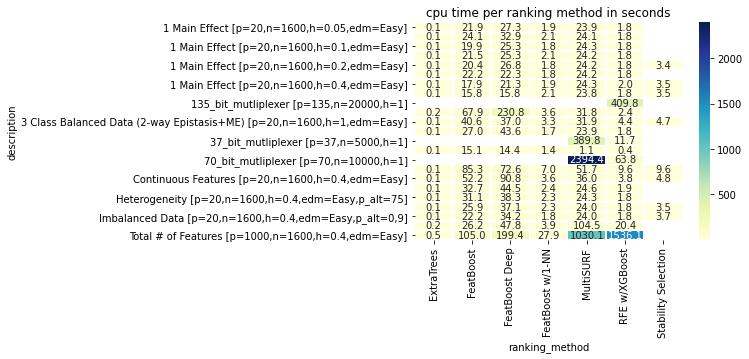

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt
pivot = pd.pivot_table(rankdata,\
    values='cpu_time', index=['description'], columns=['ranking_method'])
g = sns.heatmap(pivot, annot=True, fmt=".1f", linewidths=.5, cmap="YlGnBu")
plt.title('cpu time per ranking method in seconds')

Recall per algorithm iteration.

In [24]:
import numpy as np

statdata = pd.DataFrame() # data, statistically post-processed

for description, rankset in rankdata.groupby('description'):
    p_informatives = np.unique(rankset['p_informative'].values)
    if pd.isna(p_informatives).any():
        print('skipping {}, because `p_informative` not set (p_informatives={}).'\
            .format(description, p_informatives))
        continue
    
    p_informative = [int(x) for x in p_informatives[0].split(',')]
    # print('p_informative', p_informative)
    for ranking_method, method_rankset in rankset.groupby('ranking_method'):
        print(description, ranking_method, len(method_rankset))
        # print('replicas', np.unique(method_rankset['replica_no'].values))
        for replica_no, replica_rankset in method_rankset.groupby('replica_no'):
            for feature_rank, ranks in replica_rankset.groupby('feature_rank'):
                subset_rows = replica_rankset[replica_rankset['feature_rank'] <= feature_rank]
                subset = subset_rows['feature_index'].values
                # print('feature_rank =', feature_rank, 'subset =', subset)

                n_positives = len(subset)
                n_true_positives = np.sum(np.isin(subset, p_informative))
                n_false_positives = n_positives - n_true_positives
                n_false_negatives = len(p_informative) - n_true_positives
                recall = n_true_positives / len(p_informative)
                precision = n_true_positives / n_positives
                # print(recall, precision)
                stat = {
                    'n_positives': n_positives,
                    'n_true_positives': n_true_positives,
                    'n_false_positives': n_false_positives,
                    'n_false_negatives': n_false_negatives,
                    'recall': recall,
                    'precision': precision
                }
                # print(pd.DataFrame(ranks).assign(**stat))
                # print(ranks.assign(**stat))
                statdata = statdata.append(ranks.assign(**stat))

                # break
    #         break
    #     break
    # break
statdata.shape

SyntaxError: invalid syntax (<ipython-input-24-84d188bf5ae6>, line 5)